In [1]:
import numpy as np
import torch 
import copy 
import networkx as nx
import time 

import sys
sys.path.append('..') 

import matplotlib.pyplot as plt 

from agfn.gym import LogRewardSlightlyComplex, LogReward, MAG, LogRewardR
from agfn.models import ForwardPolicy, ForwardPolicyGNN, BackwardPolicy 
from agfn.gflownet import GFlowNet 

from agfn.utils import train, init_logz, marginal_dist_batch

torch.set_default_dtype(torch.float64)

In [2]:
class Config:

    # environment  
    num_nodes = 8
    max_degree = 4
    num_samples = 500 
    
    # models   
    hidden_dim = 128 
    num_layers = 3 
    
    # device 
    device = 'cuda' if torch.cuda.is_available() else 'cpu' 

    # training 
    epochs = 3000 
    lr = 3e-4
    lr_logz = 1e-1 
    batch_size = 128 

config = Config() 

In [3]:
def create_pol(config: Config):
    pf = ForwardPolicy(
        num_nodes=config.num_nodes, hidden_dim=config.hidden_dim, num_layers=config.num_layers, device=config.device
    )
    pb = BackwardPolicy(device=config.device)
    return pf, pb 

## Train an AGFN with a simple reward

In [37]:
log_reward_simple = LogRewardSlightlyComplex(num_nodes=config.num_nodes, device=config.device) 

pf, pb = create_pol(config) 

In [38]:
gflownet = GFlowNet(
    pf=pf, pb=pb, criterion='tb', device=config.device
)

In [39]:
initial_state = MAG(
    num_nodes=config.num_nodes, 
    batch_size=config.batch_size, 
    log_reward=log_reward_simple, 
    max_degree=config.max_degree, 
    device=config.device
)

In [40]:
losses = train(
    gflownet, initial_state, epochs=config.epochs, lr=config.lr, lr_logz=config.lr_logz
)

  3%|▎         | 84/3000 [00:05<03:13, 15.05it/s, loss=579]


KeyboardInterrupt: 

In [33]:
# Ensure all sampled graphs are MAGs 
for _ in range(64):
    assert gflownet.sample(
        copy.deepcopy(initial_state)
    ).is_mag().all()

In [37]:
num_batches = 32 
learned_dist, target_dist = marginal_dist_batch(
    gflownet, initial_state, num_batches=num_batches 
)
print(
    (learned_dist - target_dist).abs().sum() / (2 * num_batches) 
)

tensor(0.1590, device='cuda:0')


## Use a true log-reward

In [74]:
## Simulate data
simulated_dag, simulated_data = MAG.generate_dag_with_bounded_degree(
    config.num_nodes, max_degree=2, num_samples=config.num_samples, device=config.device
)

In [75]:
log_reward = LogReward(
    dataset=simulated_data, device=config.device
)

In [76]:
initial_state = MAG(
    config.num_nodes, config.batch_size, log_reward, config.max_degree, config.device
)

In [77]:
pf, pb = create_pol(config) 
gflownet = GFlowNet(
    pf=pf, pb=pb, criterion='cbf', device=config.device
)

In [78]:
log_reward.warmup(
    gflownet, initial_state, num_batches=16
)
log_reward.std.data /= log_reward.std.data 

In [79]:
gflownet.sample(
    copy.deepcopy(initial_state) 
).log_reward(), log_reward.mu

(tensor([  -61.5903,  -803.9551,  -950.3721, -1650.3101, -1653.4463,  -933.0967,
         -1745.3809,   -79.8647,  -864.7119, -2546.5010, -1782.6138, -1752.5742,
          -831.2041, -1729.2617,  -929.5054,  -937.8013, -2440.7866,  -943.9209,
          -869.4731, -1587.9995,   -96.2251, -2539.7314, -2411.7017,  -922.2993,
         -1594.7793, -2531.1279, -1713.2690, -2592.2612, -1780.5283, -1717.5464,
         -1687.2319, -1753.5635,   -70.6904,  -845.2861, -1641.3955,   -56.9146,
         -2531.8042, -1720.9531,  -965.3237, -1737.4907, -1778.6670,  -813.6265,
         -1643.0054,  -825.2539, -1820.6377, -2447.2197,  -846.2588, -1725.7617,
         -1620.5317,  -930.1821,  -948.0254,   -80.4028, -1643.8486, -1673.9839,
         -1651.2925, -1637.8184,  -885.2871,  -841.1221,  -967.7612,   -73.7300,
         -2438.8101,  -812.6177, -2527.2207, -1710.8965,   -38.9092, -2536.6494,
          -878.0576, -2325.9517, -2451.3979, -1783.7964,  -818.9692, -1682.8643,
           -43.5239,  -909.9

In [81]:
losses = train(
    gflownet, initial_state, config.epochs//3, config.lr, config.lr_logz
)

100%|██████████| 1000/1000 [02:00<00:00,  8.30it/s, loss=3.83]  


In [82]:
initial_state_inference = MAG(
    config.num_nodes, config.batch_size, log_reward, config.max_degree, device=config.device
)
state_inference = gflownet.sample(initial_state_inference) 

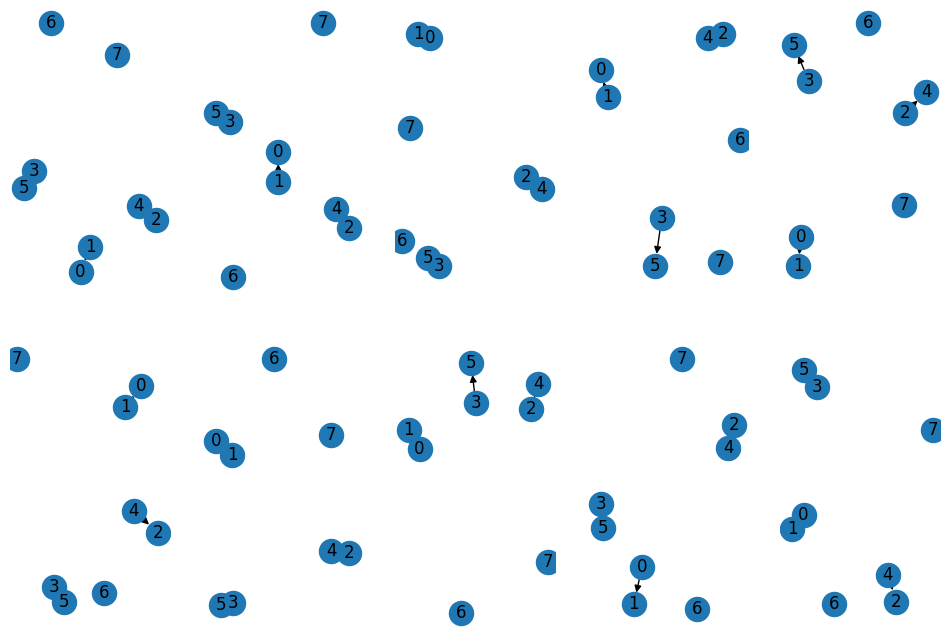

In [83]:
log_rewards = state_inference.log_reward() 
indices = torch.topk(log_rewards, k=10).indices 

plt.figure(figsize=(12, 8))
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    state_inference.draw(i) 

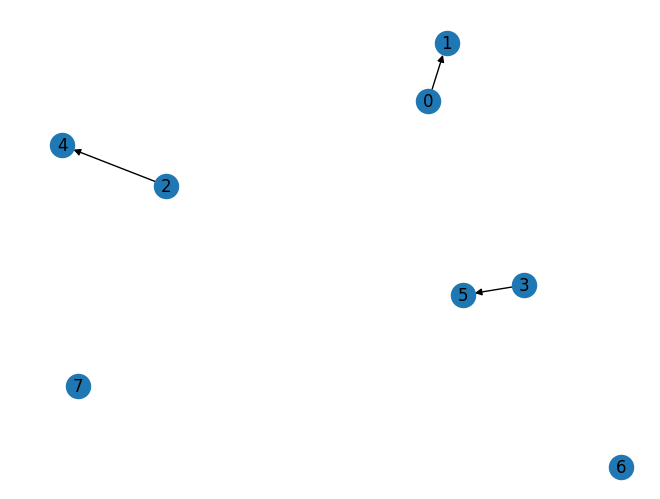

In [84]:
import networkx as nx
nx.draw(simulated_dag, with_labels=True)

## Use a different data set to assess the model

In [4]:
import pandas as pd
dataset = pd.read_csv('../data/chain4_dat01.csv')
node_labels = dataset.columns.tolist() 
config.num_nodes = dataset.shape[1] 

data = torch.tensor(
    dataset.values, dtype=torch.get_default_dtype()
)

In [5]:
chain4_dag = nx.DiGraph() 
chain4_dag.add_nodes_from(
    [0, 1, 2, 3]
)
chain4_dag.add_edges_from(
    [(0, 1), (1, 2), (2, 3)] 
)

config.num_nodes = 4
config.num_samples = 1000
config.max_degree = 2

In [6]:
simulated_dag, simulated_data, simulated_mag = MAG.generate_dag_with_bounded_degree(
    config.num_nodes, 
    config.max_degree, 
    config.num_samples, 
    device=config.device, 
    beta_scale=.5, 
    beta_loc=0., 
    omega_scale=.1,
    omega_loc=.1, 
    nx_dag=chain4_dag,
    return_mag=True
)

In [7]:
log_reward_torch = LogReward(
    torch.tensor(dataset.values, dtype=torch.get_default_dtype()), device=config.device, gamma=1.
)

log_reward = LogRewardR(
    dataset, device=config.device
)

R[write to console]: 
Attaching package: ‘igraph’


R[write to console]: The following objects are masked from ‘package:stats’:

    decompose, spectrum


R[write to console]: The following object is masked from ‘package:base’:

    union


R[write to console]: Carregando pacotes exigidos: lavaan

R[write to console]: This is lavaan 0.6-18
lavaan is FREE software! Please report any bugs.

R[write to console]: 
Attaching package: ‘SEMgraph’


R[write to console]: The following object is masked from ‘package:lavaan’:

    parameterEstimates




In [8]:
config.batch_size = 8
initial_state = MAG(   
    config.num_nodes, config.batch_size, log_reward, config.max_degree, device=config.device
)

In [9]:
pf, pb = create_pol(config) 
gflownet = GFlowNet(
    pf, pb, criterion='cbf', device=config.device
)

In [11]:
envs = gflownet.sample(initial_state)

t = time.time() 
print( log_reward(envs) ) 
print(time.time() - t)
t = time.time() 
print( log_reward_torch(envs) ) 
print(time.time() - t)

tensor([-5539.5787, -4269.1188, -4271.9699,     0.0000, -5692.6672, -5538.7045,
        -2843.0074, -4118.5167], device='cuda:0')
0.22911620140075684
tensor([-5509.4284, -5654.0589, -5662.7527, -5630.0226, -5662.6725, -5508.6774,
        -5637.0290, -5509.3281], device='cuda:0')
0.011535406112670898


In [30]:
log_reward.warmup(
    gflownet=gflownet, initial_state=initial_state, num_batches=32
)
log_reward.std.data /= log_reward.std.data 

TypeError: cannot pickle 'SignatureTranslatedAnonymousPackage' object

In [11]:
gflownet.sample(
    copy.deepcopy(initial_state)
).log_reward(), log_reward.mu

(tensor([ -68.9639,  -94.1729, -250.4624, -233.3982,  -18.3835,  -86.5183,
          -86.0613, -149.4971, -242.7751,   -8.1443,  -86.1736, -146.3167,
          -86.3376, -122.7524, -111.6399, -111.2434, -112.0823, -250.4624,
         -242.7200, -242.7810,  -83.8958, -112.0823,  -85.8418,  -17.4663,
          -38.8000, -149.1118, -103.1841, -258.6072, -111.8323, -123.6580,
         -173.5500, -179.0278, -249.4470,  -11.3630, -198.2590, -250.4624,
         -138.8835, -242.7751, -207.3464, -202.4595,  -18.4268, -138.9355,
         -180.5068, -123.3838, -122.7773,  -86.0063, -202.4595, -173.7571,
         -243.1785,  -93.0308, -249.4827, -250.4624, -173.4988,  -47.2510,
          -86.3635, -156.1868, -111.6399, -112.0823, -180.5068, -155.9446,
         -240.3530,  -86.0059,  -75.7507, -199.2834,  -17.6597,  -86.3452,
         -155.9446,  -17.9802,  -86.3706, -249.3196,  -47.2520, -115.9578,
         -140.1458, -178.6230, -202.4595, -115.2878, -112.1121, -112.1111,
         -178.2732, -250.

In [14]:
losses = train(
    gflownet, initial_state, epochs=config.epochs, lr=config.lr, lr_logz=config.lr_logz 
)

100%|██████████| 3000/3000 [02:45<00:00, 18.14it/s, loss=0.237]  


In [15]:
initial_state_inference = MAG(
    config.num_nodes, config.batch_size, log_reward, config.max_degree, device=config.device
)
state_inference = gflownet.sample(initial_state_inference) 

tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')
tensor(0., device='cuda:0') tensor([-8.1438], device='cuda:0')


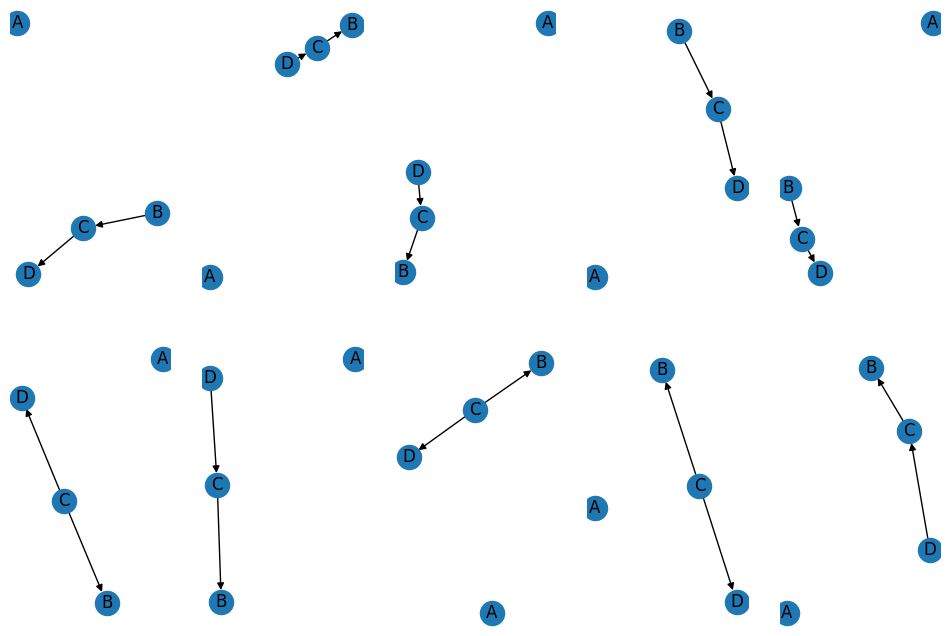

In [19]:
log_rewards = state_inference.log_reward() 
indices = torch.topk(log_rewards, k=10).indices 

plt.figure(figsize=(12, 8))
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)
    print(
        log_rewards[i], log_reward(simulated_mag)
    )  
    state_inference.draw(i, labels=node_labels) 

In [ ]:
from causallearn.search.ConstraintBased.FCI import fci

# default parameters
g, edges = fci(simulated_data.cpu().numpy())

edges

Depth=0, working on node 3: 100%|██████████| 4/4 [00:00<00:00, 699.11it/s]
